# Code Exiobase_EU_ETS_2 by Martínez-Hernando


This information is necessary in Python, for activate the funtions 
If they are not installed is necessary to do it, write pip install XXXXX. If pip doesn't work put pip3, or pip3.11 (search on internet)

Activate generical information

In [7]:
import pandas as pd #To real CSV and dataframes
import numpy as np #To work with matrix

To create list

In [8]:
from typing import List, Tuple, Dict, Callable, Iterable, Union

 # To use pymrio

In [9]:
import pymrio as mr

Declare new IO system

In [10]:
exio3311=mr.IOSystem()
exio3350=mr.IOSystem()
exio3380=mr.IOSystem()
exio33100=mr.IOSystem()

## Importing EXIOBASE 3.3.18 data
We will only import:
- $Z$, the intermediate consumption,
- $Y$, the final demand,
- $F$ and $F_Y$, the environmental extensions, only for air emissions.

In [11]:
exiobase_folder="P:/Universidad/Exiobase/" #Put here your folder where you have download Exiobase with /, no with \

Z (Intermediate products)

In [12]:
Z_raw=pd.read_csv(exiobase_folder + "MR_HIOT_2011_v3_3_18_by_product_technology.csv", #You should have this name of file, if not change it
                    index_col = [0,1,2,3,4],
                    header = [0,1,2,3])
Z_raw.head() #To see the first lines

AU  \
                                               Cultivation of paddy rice   
                                                                   i01.a   
                                                                  A_PARI   
AU Paddy rice              p01.a C_PARI tonnes                       0.0   
   Wheat                   p01.b C_WHEA tonnes                       0.0   
   Cereal grains nec       p01.c C_OCER tonnes                       0.0   
   Vegetables, fruit, nuts p01.d C_FVEG tonnes                       0.0   
   Oil seeds               p01.e C_OILS tonnes                       0.0   

                                                                     \
                                               Cultivation of wheat   
                                                              i01.b   
                                                             A_WHEA   
AU Paddy rice              p01.a C_PARI tonnes                  0.0   
   Wheat                   p01.b C_WHEA tonnes                  0.0   
   Cereal grains nec       p01.c C_OCER tonnes                  0.0   
   Vegetables, fruit, nuts p01.d C_FVEG tonnes                  0.0   
   Oil seeds               p01.e C_OILS tonnes                  0.0   

                                                                                 \
                                               Cultivation of cereal grains nec   
                                                                          i01.c   
                                                                         A_OCER   
AU Paddy rice              p01.a C_PARI tonnes                          0.00000   
   Wheat                   p01.b C_WHEA tonnes                          0.00000   
   Cereal grains nec       p01.c C_OCER tonnes                      70942.96547   
   Vegetables, fruit, nuts p01.d C_FVEG tonnes                          0.00000   
   Oil seeds               p01.e C_OILS tonnes                          0.00000   

                                                                                       \
                                               Cultivation of vegetables, fruit, nuts   
                                                                                i01.d   
                                                                               A_FVEG   
AU Paddy rice              p01.a C_PARI tonnes                                0.00000   
   Wheat                   p01.b C_WHEA tonnes                                0.00000   
   Cereal grains nec       p01.c C_OCER tonnes                                0.00000   
   Vegetables, fruit, nuts p01.d C_FVEG tonnes                            18266.75262   
   Oil seeds               p01.e C_OILS tonnes                                0.00000   

                                                                         \
                                               Cultivation of oil seeds   
                                                                  i01.e   
                                                                 A_OILS   
AU Paddy rice              p01.a C_PARI tonnes                      0.0   
   Wheat                   p01.b C_WHEA tonnes                      0.0   
   Cereal grains nec       p01.c C_OCER tonnes                      0.0   
   Vegetables, fruit, nuts p01.d C_FVEG tonnes                      0.0   
   Oil seeds               p01.e C_OILS tonnes                      0.0   

                                                                                      \
                                               Cultivation of sugar cane, sugar beet   
                                                                               i01.f   
                                                                              A_SUGB   
AU Paddy rice              p01.a C_PARI tonnes                                   0.0   
   Wheat                   p01.b C_WHEA tonnes                                 

In [13]:
Z_reindexed=Z_raw.droplevel([2,3,4], axis=0).copy() #To remove useless rows
Z_reindexed.index.names=["region","sector"]
Z_reindexed.columns=Z_reindexed.index
Z_reindexed.head()


region                                 AU                          \
sector                         Paddy rice Wheat Cereal grains nec   
region sector                                                       
AU     Paddy rice                     0.0   0.0           0.00000   
       Wheat                          0.0   0.0           0.00000   
       Cereal grains nec              0.0   0.0       70942.96547   
       Vegetables, fruit, nuts        0.0   0.0           0.00000   
       Oil seeds                      0.0   0.0           0.00000   

region                                                            \
sector                         Vegetables, fruit, nuts Oil seeds   
region sector                                                      
AU     Paddy rice                              0.00000       0.0   
       Wheat                                   0.00000       0.0   
       Cereal grains nec                       0.00000       0.0   
       Vegetables, fruit, nuts             18266.75262       0.0   
       Oil seeds                               0.00000       0.0   

region                                                                    \
sector                         Sugar cane, sugar beet Plant-based fibers   
region sector                                                              
AU     Paddy rice                                 0.0               0.00   
       Wheat                                      0.0               0.00   
       Cereal grains nec                          0.0               0.00   
       Vegetables, fruit, nuts                    0.0               0.00   
       Oil seeds                                  0.0        -1206065.87   

region                                                                 ...  \
sector                         Crops nec        Cattle           Pigs  ...   
region sector                                                          ...   
AU     Paddy rice                    0.0  0.000000e+00       0.000000  ...   
       Wheat                         0.0  6.791574e+05  156083.893300  ...   
       Cereal grains nec             0.0  2.277000e+06  823314.442100  ...   
       Vegetables, fruit, nuts       0.0  1.552051e+03     255.322381  ...   
       Oil seeds                     0.0  0.000000e+00       0.000000  ...   

region                                                    WM  \
sector                         Paper for treatment: landfill   
region sector                                                  
AU     Paddy rice                                        0.0   
       Wheat                                             0.0   
       Cereal grains nec                                 0.0   
       Vegetables, fruit, nuts                           0.0   
       Oil seeds                                         0.0   

region                                                                \
sector                         Plastic waste for treatment: landfill   
region sector                                                          
AU     Paddy rice                                                0.0   
       Wheat                                                     0.0   
       Cereal grains nec                                         0.0   
       Vegetables, fruit, nuts                                   0.0   
       Oil seeds                                                 0.0   

region                                                                              \
sector                         Inert/metal/hazardous waste for treatment: landfill   
region sector                                                                        
AU     Paddy rice                                                             0.0    
       Wheat                                                                  0.0    
       Cereal grains nec                                                      0.0    
       Vegetables, fruit, nuts                                

In [14]:
exio3311.Z=Z_reindexed

Y (Final demand)

In [15]:
Y_raw = pd.read_csv(exiobase_folder + "MR_HIOT_2011_v3_3_18_FD.csv", #You should have this name of file, if not change it
                    index_col = [0,1,2,3,4],
                    header = [0,1,2,3])

Y_reindexed=Y_raw.droplevel([2,3], axis=1).copy() #To remove useless columns
Y_reindexed.index=Z_reindexed.index
Y_reindexed.columns.names=["region", "sector"] #To name the columns
exio3311.Y=Y_reindexed

X (total production)

In [16]:
X_raw = pd.read_csv(exiobase_folder + "MR_HIOT_2011_v3_3_18_principal_production.csv", #You should have this name of file, if not change it
                    header = [0,1,2,3,4,5,6,7])

X_reindexed=X_raw.droplevel([2,3,4,5,6,7], axis=1).copy()
X_reindexed.columns=exio3311.Z.columns #To rename the columns
X_reindexed.index=['Total production'] #To rename the index
exio3311.x=X_reindexed.T

F and F_Y (Extensions, total emissions per activity)

In [17]:
exio3311.emissions=mr.Extension("emissions")
F_raw = pd.read_excel(exiobase_folder + "MR_HIOT_2011_v3_3_18_extensions.xlsx", #This data is emissions of intermediate production
                      sheet_name="Emiss_act", #You should have this name of file, if not change it.
                      index_col=[0,1,2],
                      header=[0,1,2,3])
F_raw.columns=Z_reindexed.columns

F_Y_raw=pd.read_excel(exiobase_folder + "MR_HIOT_2011_v3_3_18_extensions.xlsx", #This data is emissions of final demand
                      sheet_name="Emiss_FD", #You should have this name of file, if not change it.
                      index_col=[0,1,2],
                      header=[0,1,2,3])
F_Y_raw.columns=Y_reindexed.columns

F_raw.head()
F_Y_raw.head()
exio3311.emissions.F=F_raw
exio3311.emissions.F_Y=F_Y_raw

Equilibrium in electricity mix

In [18]:
init_elec=95
finit_elec=init_elec+11
exio3311.Z.iloc[finit_elec,:]
for i in range (48):
    init_elec_i=init_elec+i*164
    finit_elec_i=finit_elec+i*164
    total_electricity_i=exio3311.x.iloc[init_elec_i:finit_elec_i,:]
    total_elec_sum=total_electricity_i.sum()
    perc_elect_i=total_electricity_i/total_elec_sum
    for j in range(len(exio3311.Z.columns)):
        elec_j=exio3311.Z.iloc[init_elec_i:finit_elec_i,j]
        elec_j_sum=elec_j.sum()
        new_elec_j=elec_j_sum*perc_elect_i
        exio3311.Z.iloc[init_elec_i:finit_elec_i,j]=new_elec_j


# Updating the electricity mix to 2030

Vector of variation of electricity mix (lambda). Most numbers are ones because they are not electricity mix

In [19]:
vector_lambda_30=pd.read_csv(exiobase_folder + "MR_2030_lambda_PNIEC_IEA_al.csv", #You should have this name of file, if not change it
                    index_col = [0,1],
                    header = [0])
vector_lambda_30=vector_lambda_30.iloc[:, 0]
vector_lambda_30.index=exio3311.Z.index
vector_lambda_30=vector_lambda_30.squeeze()
vector_lambda_30

region  sector                                           
AU      Paddy rice                                           1.0
        Wheat                                                1.0
        Cereal grains nec                                    1.0
        Vegetables, fruit, nuts                              1.0
        Oil seeds                                            1.0
                                                            ... 
WM      Membership organisation services n.e.c. (91)         1.0
        Recreational, cultural and sporting services (92)    1.0
        Other services (93)                                  1.0
        Private households with employed persons (95)        1.0
        Extra-territorial organizations and bodies           1.0
Name: Value_100, Length: 7872, dtype: float64

Creation of new Z that multiplies columns and raws by lambda

In [21]:
Z_100=exio3311.Z.mul(vector_lambda_30, axis=0)
Z_100=Z_100.mul(vector_lambda_30, axis=1)

Comprobation

In [23]:
print(exio3311.Z.loc[('ES','Electricity by coal'),('ES','Bottles for treatment, Recycling of bottles by direct reuse')])
print(vector_lambda_30.loc[('ES','Electricity by coal')])
Z_100.loc[('ES','Electricity by coal'),('ES','Bottles for treatment, Recycling of bottles by direct reuse')]


28.77233375922825
0.181635969


np.float64(5.226090722748836)

Z modified to update activities which in 2011 has no production of one type of electricity and in 2022 they have. It has been done using the proportion of rows and columns of the region where country is or a near country

In [24]:
Z_gamma=pd.read_csv(exiobase_folder + "MR_HIOT_2011_v3_3_18_Z_gamma.csv", #You should have this name of file, if not change it
                    index_col = [0,1],
                    header = [0,1])
Z_gamma.index=exio3311.Z.index
Z_gamma.columns=exio3311.Z.columns
Z_gamma #To see the first lines

region                                                           AU        \
sector                                                   Paddy rice Wheat   
region sector                                                               
AU     Paddy rice                                                 0     0   
       Wheat                                                      0     0   
       Cereal grains nec                                          0     0   
       Vegetables, fruit, nuts                                    0     0   
       Oil seeds                                                  0     0   
...                                                             ...   ...   
WM     Membership organisation services n.e.c. (91)               0     0   
       Recreational, cultural and sporting services (92)          0     0   
       Other services (93)                                        0     0   
       Private households with employed persons (95)              0     0   
       Extra-territorial organizations and bodies                 0     0   

region                                                                      \
sector                                                   Cereal grains nec   
region sector                                                                
AU     Paddy rice                                                        0   
       Wheat                                                             0   
       Cereal grains nec                                                 0   
       Vegetables, fruit, nuts                                           0   
       Oil seeds                                                         0   
...                                                                    ...   
WM     Membership organisation services n.e.c. (91)                      0   
       Recreational, cultural and sporting services (92)                 0   
       Other services (93)                                               0   
       Private households with employed persons (95)                     0   
       Extra-territorial organizations and bodies                        0   

region                                                                            \
sector                                                   Vegetables, fruit, nuts   
region sector                                                                      
AU     Paddy rice                                                              0   
       Wheat                                                                   0   
       Cereal grains nec                                                       0   
       Vegetables, fruit, nuts                                                 0   
       Oil seeds                                                               0   
...                                                                          ...   
WM     Membership organisation services n.e.c. (91)                            0   
       Recreational, cultural and sporting services (92)                       0   
       Other services (93)                                                     0   
       Private households with employed persons (95)                           0   
       Extra-territorial organizations and bodies                              0   

region                                                              \
sector                                                   Oil seeds   
region sector                                                        
AU     Paddy rice                                                0   
       Wheat                                                     0   
       Cereal grains nec                                         0   
       Vegetables, fruit, nuts                                   0   
       Oil seeds                                                 0   
...                                                            ...   
WM     Membership org

In [25]:
Z_gamma.isna().values.any() #To check all data is ok, is have to be false

np.False_

In [26]:
Z_new=Z_100+Z_gamma
Z_new

region                                                           AU            \
sector                                                   Paddy rice     Wheat   
region sector                                                                   
AU     Paddy rice                                          0.000000  0.000000   
       Wheat                                               0.000000  0.000000   
       Cereal grains nec                                   0.000000  0.000000   
       Vegetables, fruit, nuts                             0.000000  0.000000   
       Oil seeds                                           0.000000  0.000000   
...                                                             ...       ...   
WM     Membership organisation services n.e.c. (91)        0.000351  0.001041   
       Recreational, cultural and sporting services (92)   0.000000  0.000148   
       Other services (93)                                 0.000060  0.000216   
       Private households with employed persons (95)       0.000000  0.000000   
       Extra-territorial organizations and bodies          0.000000  0.000000   

region                                                                      \
sector                                                   Cereal grains nec   
region sector                                                                
AU     Paddy rice                                                 0.000000   
       Wheat                                                      0.000000   
       Cereal grains nec                                      70942.965470   
       Vegetables, fruit, nuts                                    0.000000   
       Oil seeds                                                  0.000000   
...                                                                    ...   
WM     Membership organisation services n.e.c. (91)               0.001017   
       Recreational, cultural and sporting services (92)          0.000236   
       Other services (93)                                        0.000583   
       Private households with employed persons (95)              0.000000   
       Extra-territorial organizations and bodies                 0.000000   

region                                                                            \
sector                                                   Vegetables, fruit, nuts   
region sector                                                                      
AU     Paddy rice                                                       0.000000   
       Wheat                                                            0.000000   
       Cereal grains nec                                                0.000000   
       Vegetables, fruit, nuts                                      18266.752620   
       Oil seeds                                                        0.000000   
...                                                                          ...   
WM     Membership organisation services n.e.c. (91)                     0.003093   
       Recreational, cultural and sporting services (92)                0.006582   
       Other services (93)                                              0.000521   
       Private households with employed persons (95)                    0.000000   
       Extra-territorial organizations and bodies                       0.000000   

region                                                              \
sector                                                   Oil seeds   
region sector                                                        
AU     Paddy rice                                         0.000000   
       Wheat                                              0.000000   
       Cereal grains nec                                  0.000000   
       Vegetables, fruit, nuts                            0.000000   
       Oil seeds                                          0.000000   
...                                

New value of Z, do not run if you will edit cells below

In [27]:
exio33100.Z=Z_new
exio33100.Z
exio33100.Z.isna().values.any() #To check all data is ok, it has to be false

np.False_

New Y

In [29]:
Y_new=exio3311.Y.mul(vector_lambda_30, axis=0)
Y_new.isna().values.any() #To check all data is ok, it has to be false

np.False_

Comprobation

In [31]:
print(exio3311.Y.loc[('ES','Electricity by coal'),('ES','Final consumption expenditure by households')])
print(vector_lambda_30.loc[('ES','Electricity by coal')])
Y_new.loc[('ES','Electricity by coal'),('ES','Final consumption expenditure by households')]

64568.05815
0.181635969


np.float64(11727.881808523598)

In [32]:
exio33100.Y=Y_new

Updating emissions

In [34]:
exio33100.emissions=mr.Extension("emissions")
exio33100.emissions.F=F_raw.mul(vector_lambda_30, axis=1)
exio33100.emissions.F_Y=F_Y_raw.mul(vector_lambda_30, axis=1)

In [35]:
exio33100.emissions.F

region                                           AU                \
sector                                   Paddy rice         Wheat   
Carbon dioxide, fossil   tonnes air    37614.130823  1.941735e+06   
N2O                      tonnes air       44.091107  9.484771e+03   
CH4                      tonnes air    26527.287506  1.636370e+02   
HFCs                     tonnes air        0.000000  0.000000e+00   
PFCs                     tonnes air        0.000000  0.000000e+00   
...                                             ...           ...   
Ni                       tonnes soil       0.000000  0.000000e+00   
C                        tonnes air        0.000000  0.000000e+00   
other emissions          tonnes undef    441.223279  3.708035e+04   
Carbon dioxide, biogenic tonnes air       95.600973  5.275417e+03   
Other emissions nec      tonnes air        0.000000  0.000000e+00   

region                                                   \
sector                                Cereal grains nec   
Carbon dioxide, fossil   tonnes air       490900.537062   
N2O                      tonnes air         3883.981264   
CH4                      tonnes air          137.839621   
HFCs                     tonnes air            0.000000   
PFCs                     tonnes air            0.000000   
...                                                 ...   
Ni                       tonnes soil           0.000000   
C                        tonnes air            0.000000   
other emissions          tonnes undef      35399.145759   
Carbon dioxide, biogenic tonnes air         1213.379428   
Other emissions nec      tonnes air            0.000000   

region                                                                       \
sector                                Vegetables, fruit, nuts     Oil seeds   
Carbon dioxide, fossil   tonnes air             245169.420806  83062.646179   
N2O                      tonnes air               8398.948592    463.542942   
CH4                      tonnes air                 66.855406     20.566199   
HFCs                     tonnes air                  0.000000      0.000000   
PFCs                     tonnes air                  0.000000      0.000000   
...                                                       ...           ...   
Ni                       tonnes soil                 0.000000      0.000000   
C                        tonnes air                  0.000000      0.000000   
other emissions          tonnes undef            60146.634050  37651.268801   
Carbon dioxide, biogenic tonnes air                566.437671    186.505849   
Other emissions nec      tonnes air                  0.000000      0.000000   

region                                                        \
sector                                Sugar cane, sugar beet   
Carbon dioxide, fossil   tonnes air            173071.251514   
N2O                      tonnes air              1161.180932   
CH4                      tonnes air                22.100891   
HFCs                     tonnes air                 0.000000   
PFCs                     tonnes air                 0.000000   
...                                                      ...   
Ni                       tonnes soil                0.000000   
C                        tonnes air                 0.000000   
other emissions          tonnes undef            3348.404272   
Carbon dioxide, biogenic tonnes air               217.369557   
Other emissions nec      tonnes air                 0.000000   

region                                                                 \
sector                                Plant-based fibers    Crops nec   
Carbon dioxide, fossil   tonnes air        151751.515526  4103.943658   
N2O                      tonnes air          1166.262681     2.362630   
CH4                      tonnes air            12.581706     0.422404   
HFCs                     tonnes air             0.000000     0.000000   
PFCs                     tonnes air

In [36]:
exio33100.reset_all_full() #reset
exio33100.calc_all() #calculation of the rest of matrix again

# Updating electricity mix to 2030 50% targets

Vector of variation of electricity mix (lambda). Most numbers are ones because they are not electricity mix

In [37]:
vector_lambda_50=pd.read_csv(exiobase_folder + "MR_2030_lambda_PNIEC_IEA_al.csv", #You should have this name of file, if not change it
                    index_col = [0,1],
                    header = [0])
vector_lambda_50=vector_lambda_50.iloc[:, 2]
vector_lambda_50.index=exio3311.Z.index
vector_lambda_50=vector_lambda_50.squeeze()
vector_lambda_50

region  sector                                           
AU      Paddy rice                                           1.0
        Wheat                                                1.0
        Cereal grains nec                                    1.0
        Vegetables, fruit, nuts                              1.0
        Oil seeds                                            1.0
                                                            ... 
WM      Membership organisation services n.e.c. (91)         1.0
        Recreational, cultural and sporting services (92)    1.0
        Other services (93)                                  1.0
        Private households with employed persons (95)        1.0
        Extra-territorial organizations and bodies           1.0
Name: Value_50, Length: 7872, dtype: float64

Creation of new Z that multiplies columns and raws by lambda

In [38]:
Z_50=exio3311.Z.mul(vector_lambda_50, axis=0)
Z_50=Z_50.mul(vector_lambda_50, axis=1)

In [39]:
Z_new_50=Z_50+Z_gamma

New value of Z, do not run if you will edit cells below

In [40]:
exio3350.Z=Z_new_50
exio3350.Z.isna().values.any() #To check all data is ok, it has to be false

np.False_

In [41]:
print(exio3311.Z.loc[('PL','Electricity by coal'),('PL','Copper products')])
print(vector_lambda_50.loc[('ES','Electricity by coal')])
Z_new_50.loc[('PL','Electricity by coal'),('PL','Copper products')]

805.5152157144722
0.181635969


np.float64(650.5446557651227)

New Y

In [42]:
Y_new_50=exio3311.Y.mul(vector_lambda_50, axis=0)
Y_new_50.isna().values.any() #To check all data is ok, it has to be false

np.False_

In [43]:
print(exio3311.Y.loc[('ES','Electricity by coal'),('ES','Final consumption expenditure by households')])
print(vector_lambda_50.loc[('ES','Electricity by coal')])
Y_new_50.loc[('ES','Electricity by coal'),('ES','Final consumption expenditure by households')]

64568.05815
0.181635969


np.float64(11727.881808523598)

In [44]:
exio3350.Y=Y_new_50

Adding emissions to new system

In [45]:
exio3350.emissions=mr.Extension("emissions")
exio3350.emissions.F=F_raw.mul(vector_lambda_50, axis=1)
exio3350.emissions.F_Y=F_Y_raw.mul(vector_lambda_50, axis=1)

Calculations for 2030 50%

In [46]:
exio3350.reset_all_full() #reset
exio3350.calc_all() #calculation of the rest of matrix again

# Updating electricity mix to 2030 80% targets

In [47]:
vector_lambda_80=pd.read_csv(exiobase_folder + "MR_2030_lambda_PNIEC_IEA_al.csv", #You should have this name of file, if not change it
                    index_col = [0,1],
                    header = [0])
vector_lambda_80=vector_lambda_80.iloc[:, 1]
vector_lambda_80.index=exio3311.Z.index
vector_lambda_80=vector_lambda_80.squeeze()
vector_lambda_80

region  sector                                           
AU      Paddy rice                                           1.0
        Wheat                                                1.0
        Cereal grains nec                                    1.0
        Vegetables, fruit, nuts                              1.0
        Oil seeds                                            1.0
                                                            ... 
WM      Membership organisation services n.e.c. (91)         1.0
        Recreational, cultural and sporting services (92)    1.0
        Other services (93)                                  1.0
        Private households with employed persons (95)        1.0
        Extra-territorial organizations and bodies           1.0
Name: Value_80, Length: 7872, dtype: float64

In [48]:
Z_80=exio3311.Z.mul(vector_lambda_80, axis=0)
Z_80=Z_80.mul(vector_lambda_80, axis=1)

In [49]:
Z_new_80=Z_80+Z_gamma

In [50]:
exio3380.Z=Z_new_80
exio3380.Z.isna().values.any() #To check all data is ok, it has to be false

np.False_

In [51]:
Y_new_80=exio3311.Y.mul(vector_lambda_80, axis=0)
Y_new_80.isna().values.any() #To check all data is ok, it has to be false

np.False_

In [52]:
exio3380.Y=Y_new_80

In [53]:
exio3380.emissions=mr.Extension("emissions")
exio3380.emissions.F=F_raw.mul(vector_lambda_80, axis=1)
exio3380.emissions.F_Y=F_Y_raw.mul(vector_lambda_80, axis=1)

In [54]:
exio3380.reset_all_full() #reset
exio3380.calc_all() #calculation of the rest of matrix again

# Supply chains

To no change everything
11= 100%
22= 50%
30= 80%

Chain 2 DE

In [55]:
country_metal_2='DE'
mining='Aluminium ores and concentrates'
metal='Aluminium and aluminium products'

impact_metal_2t11=exio33100.emissions.S*exio33100.L.loc[:,(country_metal_2,metal)]
impact_metal_2t11=impact_metal_2t11.T

impact_mining_211=impact_metal_2t11.copy()
impact_mining_211.loc[impact_mining_211.index.get_level_values("sector")!=mining,:]=0
impact_metal_211=impact_metal_2t11.copy()
impact_metal_211.loc[impact_metal_211.index.get_level_values("sector")==mining,:]=0

impact_metal_2t=exio3350.emissions.S*exio3350.L.loc[:,(country_metal_2,metal)]
impact_metal_2t=impact_metal_2t.T

impact_mining_2=impact_metal_2t.copy()
impact_mining_2.loc[impact_mining_2.index.get_level_values("sector") != mining, :] = 0
impact_metal_2=impact_metal_2t.copy()
impact_metal_2.loc[impact_metal_2.index.get_level_values("sector") == mining, :] = 0

impact_metal_2t30=exio3380.emissions.S*exio3380.L.loc[:,(country_metal_2,metal)]
impact_metal_2t30=impact_metal_2t30.T

impact_mining_230=impact_metal_2t30.copy()
impact_mining_230.loc[impact_mining_230.index.get_level_values("sector") != mining, :] = 0
impact_metal_230=impact_metal_2t30.copy()
impact_metal_230.loc[impact_metal_230.index.get_level_values("sector") == mining, :] = 0

In [56]:
impact_mining_boats_211=impact_mining_211.copy()
impact_mining_boats_211.values[:]=0
impact_mining_trucks_211=impact_mining_211.copy()
impact_mining_trucks_211.values[:]=0
for row_i,row in impact_mining_2.iterrows():
    i=row_i[0]  # Get the region from the row index
    if impact_mining_211.loc[(i,mining),('Carbon dioxide, fossil','tonnes','air')]!=0:
        impact_mining_region=exio33100.emissions.S*exio33100.L.loc[:,(i,mining)]
        impact_mining_region=impact_mining_region.iloc[0,:]
        impact_mining_boats_i=impact_mining_region.xs("Sea and coastal water transportation services",level="sector",axis=0).sum()/impact_mining_region.sum()
        impact_mining_trucks_i=impact_mining_region.xs("Other land transportation services",level="sector",axis=0).sum()/impact_mining_region.sum()
        impact_mining_boats_211.loc[(i,'Sea and coastal water transportation services'),:]=impact_mining_boats_i*impact_mining_211.loc[(i,mining),:]
        impact_mining_trucks_211.loc[(i,'Other land transportation services'),:]=impact_mining_trucks_i*impact_mining_211.loc[(i,mining),:]


In [57]:
impact_mining_boats_2=impact_mining_2.copy()
impact_mining_boats_2.values[:] = 0
impact_mining_trucks_2=impact_mining_2.copy()
impact_mining_trucks_2.values[:]= 0
for row_i, row in impact_mining_2.iterrows():
    i=row_i[0]  # Get the region from the row index
    if impact_mining_2.loc[(i,mining),('Carbon dioxide, fossil','tonnes','air')]!=0:
        impact_mining_region=exio3350.emissions.S*exio3350.L.loc[:,(i,mining)]
        impact_mining_region=impact_mining_region.iloc[0,:]
        impact_mining_boats_i=impact_mining_region.xs("Sea and coastal water transportation services", level="sector", axis=0).sum()/impact_mining_region.sum()
        impact_mining_trucks_i=impact_mining_region.xs("Other land transportation services", level="sector", axis=0).sum()/impact_mining_region.sum()
        impact_mining_boats_2.loc[(i,'Sea and coastal water transportation services'),:]=impact_mining_boats_i*impact_mining_2.loc[(i,mining),:]
        impact_mining_trucks_2.loc[(i,'Other land transportation services'),:]=impact_mining_trucks_i*impact_mining_2.loc[(i,mining),:]

In [58]:
impact_mining_boats_230=impact_mining_230.copy()
impact_mining_boats_230.values[:] = 0
impact_mining_trucks_230=impact_mining_230.copy()
impact_mining_trucks_230.values[:]= 0
for row_i, row in impact_mining_230.iterrows():
    i=row_i[0]  # Get the region from the row index
    if impact_mining_230.loc[(i,mining),('Carbon dioxide, fossil','tonnes','air')]!=0:
        impact_mining_region=exio3380.emissions.S*exio3380.L.loc[:,(i,mining)]
        impact_mining_region=impact_mining_region.iloc[0,:]
        impact_mining_boats_i=impact_mining_region.xs("Sea and coastal water transportation services", level="sector", axis=0).sum()/impact_mining_region.sum()
        impact_mining_trucks_i=impact_mining_region.xs("Other land transportation services", level="sector", axis=0).sum()/impact_mining_region.sum()
        impact_mining_boats_230.loc[(i,'Sea and coastal water transportation services'),:]=impact_mining_boats_i*impact_mining_230.loc[(i,mining),:]
        impact_mining_trucks_230.loc[(i,'Other land transportation services'),:]=impact_mining_trucks_i*impact_mining_230.loc[(i,mining),:]

In [59]:
impact_metal_2t11.to_csv(f'{country_metal_2}_{metal}_11.txt', sep='\t', index=True, header=True)
impact_metal_2t.to_csv(f'{country_metal_2}_{metal}.txt', sep='\t', index=True, header=True)
impact_metal_2t30.to_csv(f'{country_metal_2}_{metal}_30.txt', sep='\t', index=True, header=True)

# Calculation of equivalent emissions

Obtain transport emissions

In [60]:


impact_boats_c_mining_211=impact_mining_boats_211.iloc[:,:3].groupby(level='region').sum().T
impact_trucks_c_mining_211=impact_mining_trucks_211.iloc[:,:3].groupby(level='region').sum().T
climate_change_metal_211=impact_metal_211.iloc[:,:3].T
impact_boats_c_metal_211=climate_change_metal_211.xs("Sea and coastal water transportation services", level="sector", axis=1)
impact_trucks_c_metal_211=climate_change_metal_211.xs("Other land transportation services", level="sector", axis=1)


impact_boats_c_mining_2=impact_mining_boats_2.iloc[:,:3].groupby(level='region').sum().T
impact_trucks_c_mining_2=impact_mining_trucks_2.iloc[:,:3].groupby(level='region').sum().T
climate_change_metal_2=impact_metal_2.iloc[:,:3].T
impact_boats_c_metal_2=climate_change_metal_2.xs("Sea and coastal water transportation services", level="sector", axis=1)
impact_trucks_c_metal_2=climate_change_metal_2.xs("Other land transportation services", level="sector", axis=1)


impact_boats_c_mining_230=impact_mining_boats_230.iloc[:,:3].groupby(level='region').sum().T
impact_trucks_c_mining_230=impact_mining_trucks_230.iloc[:,:3].groupby(level='region').sum().T
climate_change_metal_230=impact_metal_230.iloc[:,:3].T
impact_boats_c_metal_230=climate_change_metal_230.xs("Sea and coastal water transportation services", level="sector", axis=1)
impact_trucks_c_metal_230=climate_change_metal_230.xs("Other land transportation services", level="sector", axis=1)


climate_change_metal=[ climate_change_metal_211.T, climate_change_metal_2.T,  climate_change_metal_230.T]
impact_boats_c_mining=[impact_boats_c_mining_211, impact_boats_c_mining_2, impact_boats_c_mining_230]
impact_trucks_c_mining=[impact_trucks_c_mining_211, impact_trucks_c_mining_2, impact_trucks_c_mining_230]
impact_boats_c_metal=[impact_boats_c_metal_211, impact_boats_c_metal_2, impact_boats_c_metal_230]
impact_trucks_c_metal=[impact_trucks_c_metal_211, impact_trucks_c_metal_2, impact_trucks_c_metal_230]


In [61]:
climate_change_metal[0]

Carbon dioxide, fossil  \
                                                                         tonnes   
                                                                            air   
region sector                                                                     
AU     Paddy rice                                                  1.737288e-07   
       Wheat                                                       5.971132e-06   
       Cereal grains nec                                           1.933582e-06   
       Vegetables, fruit, nuts                                     5.816627e-07   
       Oil seeds                                                  -2.054278e-06   
...                                                                         ...   
WM     Membership organisation services n.e.c. (91)                6.237625e-07   
       Recreational, cultural and sporting services (92)           3.580577e-06   
       Other services (93)                                         1.497410e-06   
       Private households with employed persons (95)               0.000000e+00   
       Extra-territorial organizations and bodies                  0.000000e+00   

                                                                   N2O  \
                                                                tonnes   
                                                                   air   
region sector                                                            
AU     Paddy rice                                         2.036441e-10   
       Wheat                                              2.916712e-08   
       Cereal grains nec                                  1.529841e-08   
       Vegetables, fruit, nuts                            1.992645e-08   
       Oil seeds                                         -1.146419e-08   
...                                                                ...   
WM     Membership organisation services n.e.c. (91)       0.000000e+00   
       Recreational, cultural and sporting services (92)  0.000000e+00   
       Other services (93)                                0.000000e+00   
       Private households with employed persons (95)      0.000000e+00   
       Extra-territorial organizations and bodies         0.000000e+00   

                                                                   CH4  
                                                                tonnes  
                                                                   air  
region sector                                                           
AU     Paddy rice                                         1.225219e-07  
       Wheat                                              5.032090e-10  
       Cereal grains nec                                  5.429292e-10  
       Vegetables, fruit, nuts                            1.586140e-10  
       Oil seeds                                         -5.086365e-10  
...                                                                ...  
WM     Membership organisation services n.e.c. (91)       0.000000e+00  
       Recreational, cultural and sporting services (92)  0.000000e+00  
       Other services (93)                                0.000000e+00  
       Private households with employed persons (95)      0.000000e+00  
       Extra-territorial organizations and bodies         0.000000e+00  

[7872 rows x 3 columns]

In [62]:
CF_IPCC2007=np.array([1,298, 25])#IPCC 2007 CF (CO2, N2O, CH4)
CF_IPCC2007.shape

(3,)

In [63]:
countries_list=[country_metal_2+'_100', country_metal_2+'_50',country_metal_2+'_80']

## Boat transport

Only CO2

In [64]:
M_eq_boats_2_mining=pd.DataFrame()
for number in impact_boats_c_mining:
    M_eq_boats_2_mining_i=number.iloc[0] 
    M_eq_boats_2_mining=pd.concat([M_eq_boats_2_mining, M_eq_boats_2_mining_i], axis=1)
M_eq_boats_2_mining.columns=countries_list

M_eq_boats_2_metal=pd.DataFrame()
for number in impact_boats_c_metal:
    M_eq_boats_2_metal_i=number.iloc[0] 
    M_eq_boats_2_metal=pd.concat([M_eq_boats_2_metal, M_eq_boats_2_metal_i], axis=1)
M_eq_boats_2_metal.columns=countries_list

CO2, N2O, CH4

In [65]:
M_eq_boats_3_mining=pd.DataFrame()
for number in impact_boats_c_mining:
    M_eq_boats_3_mining_i=CF_IPCC2007@number
    M_eq_boats_3_mining_i=pd.DataFrame(M_eq_boats_3_mining_i)
    M_eq_boats_3_mining_i.index=number.columns
    M_eq_boats_3_mining=pd.concat([M_eq_boats_3_mining, M_eq_boats_3_mining_i], axis=1)
M_eq_boats_3_mining.columns=countries_list

M_eq_boats_3_metal=pd.DataFrame()
for number in impact_boats_c_metal:
    M_eq_boats_3_metal_i=CF_IPCC2007@number
    M_eq_boats_3_metal_i=pd.DataFrame(M_eq_boats_3_metal_i)
    M_eq_boats_3_metal_i.index=number.columns
    M_eq_boats_3_metal=pd.concat([M_eq_boats_3_metal, M_eq_boats_3_metal_i], axis=1)
M_eq_boats_3_metal.columns=countries_list

## Road transport

Only CO2

In [66]:
M_eq_trucks_2_mining=pd.DataFrame()
for number in impact_trucks_c_mining:
    M_eq_trucks_2_mining_i=number.iloc[0] 
    M_eq_trucks_2_mining=pd.concat([M_eq_trucks_2_mining, M_eq_trucks_2_mining_i], axis=1)
M_eq_trucks_2_mining.columns=countries_list

M_eq_trucks_2_metal=pd.DataFrame()
for number in impact_trucks_c_metal:
    M_eq_trucks_2_metal_i=number.iloc[0] 
    M_eq_trucks_2_metal=pd.concat([M_eq_trucks_2_metal, M_eq_trucks_2_metal_i], axis=1)
M_eq_trucks_2_metal.columns=countries_list

CO2, N2O, CH4

In [67]:
M_eq_trucks_3_mining=pd.DataFrame()
for number in impact_trucks_c_mining:
    M_eq_trucks_3_mining_i=CF_IPCC2007@number
    M_eq_trucks_3_mining_i=pd.DataFrame(M_eq_trucks_3_mining_i)
    M_eq_trucks_3_mining_i.index=number.columns
    M_eq_trucks_3_mining=pd.concat([M_eq_trucks_3_mining, M_eq_trucks_3_mining_i], axis=1)
M_eq_trucks_3_mining.columns=countries_list

M_eq_trucks_3_metal=pd.DataFrame()
for number in impact_trucks_c_metal:
    M_eq_trucks_3_metal_i=CF_IPCC2007@number
    M_eq_trucks_3_metal_i=pd.DataFrame(M_eq_trucks_3_metal_i)
    M_eq_trucks_3_metal_i.index=number.columns
    M_eq_trucks_3_metal=pd.concat([M_eq_trucks_3_metal, M_eq_trucks_3_metal_i], axis=1)
M_eq_trucks_3_metal.columns=countries_list

In [69]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

plt.rcParams['font.family']='Times New Roman' #I prefere this font, you can change it
plt.rcParams['font.size']=16

## Cost of CO2

For price of CO2 non-EU have to been removed

In [70]:
eu_countries=['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HR', 'HU', 'IE', 'IT', 'LT', 'LU', 'LV', 'MT', 'NL', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'] #List of EU countries
price_co2_mean=196.5 #Mean price of t of co2 in EU ETS in 2030 https://doi.org/10.1016/j.esr.2023.101271 
price_co2_min=130 #Min price of t of co2 in EU ETS in 2030 https://doi.org/10.1016/j.esr.2023.101271 
price_co2_max=286 #Max price of t of co2 in EU ETS in 2030 https://doi.org/10.1016/j.esr.2023.101271 
price_co2_v=[price_co2_min, price_co2_mean, price_co2_max]

In [71]:
first=[c+'_min' for c in countries_list]
middle = countries_list.copy()
last=[c+'_max' for c in countries_list]

countries_list_3=first+middle+last

Transport in mining

In [72]:
porc_eu_mining_b=pd.DataFrame()
for j in range(3):
    number=impact_boats_c_mining[j].copy() # To get the number of the column
    if j<1:
        porc_eu_mining_b_i=number.iloc[0,:].copy()
        porc_eu_mining_b_i.values[:] = 0
        for i,row in porc_eu_mining_b_i.items():
            Mining_b=exio33100.Z.xs("Sea and coastal water transportation services", level="sector", axis=0)[(i, mining)]
            Mining_eu_b_i=Mining_b[Mining_b.index.isin(eu_countries)]
            porc_eu_mining_b_i[i]= Mining_eu_b_i.sum()/Mining_b.sum() # To calculate the porcentage of EU in transport
        porc_eu_mining_b_i=porc_eu_mining_b_i.fillna(0)
        porc_eu_mining_b=pd.concat([porc_eu_mining_b, porc_eu_mining_b_i], axis=1)  
    elif j<2:
        for i,row in porc_eu_mining_b_i.items():
            Mining_b=exio3350.Z.xs("Sea and coastal water transportation services", level="sector", axis=0)[(i, mining)]
            Mining_eu_b_i=Mining_b[Mining_b.index.isin(eu_countries)]
            porc_eu_mining_b_i[i]= Mining_eu_b_i.sum()/Mining_b.sum() # To calculate the porcentage of EU in transport
        porc_eu_mining_b_i=porc_eu_mining_b_i.fillna(0)
        porc_eu_mining_b=pd.concat([porc_eu_mining_b, porc_eu_mining_b_i], axis=1)  
    else:
        for i,row in porc_eu_mining_b_i.items():
            Mining_b=exio3380.Z.xs("Sea and coastal water transportation services", level="sector", axis=0)[(i, mining)]
            Mining_eu_b_i=Mining_b[Mining_b.index.isin(eu_countries)]
            porc_eu_mining_b_i[i]= Mining_eu_b_i.sum()/Mining_b.sum() # To calculate the porcentage of EU in transport
        porc_eu_mining_b_i=porc_eu_mining_b_i.fillna(0)
        porc_eu_mining_b=pd.concat([porc_eu_mining_b, porc_eu_mining_b_i], axis=1)
porc_eu_mining_b.columns=countries_list

C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\2164350467.py:10: RuntimeWarning: invalid value encountered in scalar divide
  porc_eu_mining_b_i[i]= Mining_eu_b_i.sum()/Mining_b.sum() # To calculate the porcentage of EU in transport
C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\2164350467.py:17: RuntimeWarning: invalid value encountered in scalar divide
  porc_eu_mining_b_i[i]= Mining_eu_b_i.sum()/Mining_b.sum() # To calculate the porcentage of EU in transport
C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\2164350467.py:24: RuntimeWarning: invalid value encountered in scalar divide
  porc_eu_mining_b_i[i]= Mining_eu_b_i.sum()/Mining_b.sum() # To calculate the porcentage of EU in transport


In [73]:
porc_eu_mining_t=pd.DataFrame()
for j in range(3):
    number=impact_trucks_c_mining[j].copy() # To get the number of the column
    if j<1:
        porc_eu_mining_t_i=number.iloc[0,:].copy()
        porc_eu_mining_t_i.values[:] = 0
        for i,row in porc_eu_mining_t_i.items():
            Mining_t=exio33100.Z.xs("Other land transportation services", level="sector", axis=0)[(i, mining)]
            Mining_eu_t_i=Mining_t[Mining_t.index.isin(eu_countries)]
            porc_eu_mining_t_i[i]= Mining_eu_t_i.sum()/Mining_t.sum() # To calculate the porcentage of EU in transport
        porc_eu_mining_t_i=porc_eu_mining_t_i.fillna(0)
        porc_eu_mining_t=pd.concat([porc_eu_mining_t, porc_eu_mining_t_i], axis=1)  
    elif j<2:
        porc_eu_mining_t_i=number.iloc[0,:].copy()
        porc_eu_mining_t_i.values[:] = 0
        for i,row in porc_eu_mining_t_i.items():
            Mining_t=exio3350.Z.xs("Other land transportation services", level="sector", axis=0)[(i, mining)]
            Mining_eu_t_i=Mining_t[Mining_t.index.isin(eu_countries)]
            porc_eu_mining_t_i[i]= Mining_eu_t_i.sum()/Mining_t.sum() # To calculate the porcentage of EU in transport
        porc_eu_mining_t_i=porc_eu_mining_t_i.fillna(0)
        porc_eu_mining_t=pd.concat([porc_eu_mining_t, porc_eu_mining_t_i], axis=1)  
    else:
        porc_eu_mining_t_i=number.iloc[0,:].copy()
        porc_eu_mining_t_i.values[:] = 0
        for i,row in porc_eu_mining_t_i.items():
            Mining_t=exio3380.Z.xs("Other land transportation services", level="sector", axis=0)[(i, mining)]
            Mining_eu_t_i=Mining_t[Mining_t.index.isin(eu_countries)]
            porc_eu_mining_t_i[i]= Mining_eu_t_i.sum()/Mining_t.sum() # To calculate the porcentage of EU in transport
        porc_eu_mining_t_i=porc_eu_mining_t_i.fillna(0)
        porc_eu_mining_t=pd.concat([porc_eu_mining_t, porc_eu_mining_t_i], axis=1)  
porc_eu_mining_t.columns=countries_list

C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\2437833944.py:10: RuntimeWarning: invalid value encountered in scalar divide
  porc_eu_mining_t_i[i]= Mining_eu_t_i.sum()/Mining_t.sum() # To calculate the porcentage of EU in transport
C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\2437833944.py:19: RuntimeWarning: invalid value encountered in scalar divide
  porc_eu_mining_t_i[i]= Mining_eu_t_i.sum()/Mining_t.sum() # To calculate the porcentage of EU in transport
C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\2437833944.py:28: RuntimeWarning: invalid value encountered in scalar divide
  porc_eu_mining_t_i[i]= Mining_eu_t_i.sum()/Mining_t.sum() # To calculate the porcentage of EU in transport


In [74]:
Cost_boats_2_mining=pd.DataFrame()
Cost_boats_3_mining=pd.DataFrame()  
Cost_trucks_2_mining=pd.DataFrame()  
Cost_trucks_3_mining=pd.DataFrame() 

for k in range(3):
    price_co2=price_co2_v[k]
    for j in countries_list:
        Cost_boats_2_mining_i=[]
        Cost_boats_3_mining_i=[]
        Cost_trucks_2_mining_i=[]  
        Cost_trucks_3_mining_i=[] 
        pos=countries_list.index(j)
        for i, region in impact_boats_c_mining[pos].items():
            if i in eu_countries:
                if porc_eu_mining_b.loc[i,j]!=0:
                    Boats_2=M_eq_boats_2_mining.loc[i,j]*price_co2*porc_eu_mining_b.loc[i,j]+M_eq_boats_2_mining.loc[i,j]*price_co2/2*(1-porc_eu_mining_b.loc[i,j])
                    Boats_3=M_eq_boats_3_mining.loc[i,j]*price_co2*porc_eu_mining_b.loc[i,j]+M_eq_boats_3_mining.loc[i,j]*price_co2/2*(1-porc_eu_mining_b.loc[i,j])
                    Trucks_2=M_eq_trucks_2_mining.loc[i,j]*price_co2*porc_eu_mining_t.loc[i,j]+M_eq_trucks_2_mining.loc[i,j]*price_co2/2*(1-porc_eu_mining_t.loc[i,j])
                    Trucks_3=M_eq_trucks_3_mining.loc[i,j]*price_co2*porc_eu_mining_t.loc[i,j]+M_eq_trucks_3_mining.loc[i,j]*price_co2/2*(1-porc_eu_mining_t.loc[i,j])
                else:
                    Boats_2=M_eq_boats_2_mining.loc[i,j]*price_co2/2*porc_eu_mining_b.loc[i,j]
                    Boats_3=M_eq_boats_3_mining.loc[i,j]*price_co2/2*porc_eu_mining_b.loc[i,j]
                    Trucks_2=M_eq_trucks_2_mining.loc[i,j]*price_co2/2*porc_eu_mining_t.loc[i,j]
                    Trucks_3=M_eq_trucks_3_mining.loc[i,j]*price_co2/2*porc_eu_mining_t.loc[i,j]
            else:
                Boats_2=0
                Boats_3=0
                Trucks_2=0
                Trucks_3=0
            Cost_boats_2_mining_i.append(Boats_2)
            Cost_boats_3_mining_i.append(Boats_3)
            Cost_trucks_2_mining_i.append(Trucks_2) 
            Cost_trucks_3_mining_i.append(Trucks_3)

        Cost_boats_2_mining_i=pd.DataFrame(Cost_boats_2_mining_i)
        Cost_boats_3_mining_i=pd.DataFrame(Cost_boats_3_mining_i)
        Cost_trucks_2_mining_i=pd.DataFrame(Cost_trucks_2_mining_i)
        Cost_trucks_3_mining_i=pd.DataFrame(Cost_trucks_3_mining_i)
        Cost_boats_2_mining=pd.concat([Cost_boats_2_mining, Cost_boats_2_mining_i], axis=1)
        Cost_boats_3_mining=pd.concat([Cost_boats_3_mining, Cost_boats_3_mining_i], axis=1)
        Cost_trucks_2_mining=pd.concat([Cost_trucks_2_mining, Cost_trucks_2_mining_i], axis=1)
        Cost_trucks_3_mining=pd.concat([Cost_trucks_3_mining, Cost_trucks_3_mining_i], axis=1)

Transport in metallurgy (including planes)

In [75]:
porc_eu_metal_b=[]
countries=[country_metal_2, country_metal_2, country_metal_2]
for j in range(3):
    if j<1:
        Metal_b=exio33100.Z.xs("Sea and coastal water transportation services", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_b= Metal_b[Metal_b.index.isin(eu_countries)]
        porc_eu_metal_b_i=Metal_eu_b.sum()/Metal_b.sum() #To calculate the porcentage of EU in transport
    elif j<8:
        Metal_b=exio3350.Z.xs("Sea and coastal water transportation services", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_b= Metal_b[Metal_b.index.isin(eu_countries)]
        porc_eu_metal_b_i=Metal_eu_b.sum()/Metal_b.sum() #To calculate the porcentage of EU in transport 
    else:
        Metal_b=exio3380.Z.xs("Sea and coastal water transportation services", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_b= Metal_b[Metal_b.index.isin(eu_countries)]
        porc_eu_metal_b_i=Metal_eu_b.sum()/Metal_b.sum() #To calculate the porcentage of EU in transport
    porc_eu_metal_b.append(porc_eu_metal_b_i)
porc_eu_metal_b=pd.DataFrame(porc_eu_metal_b)
porc_eu_metal_b=porc_eu_metal_b.T
porc_eu_metal_b.columns=countries_list

In [76]:
porc_eu_metal_t=[]
countries=[country_metal_2, country_metal_2, country_metal_2]
for j in range(3):
    if j<1:
        Metal_t=exio33100.Z.xs("Other land transportation services", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_t=Metal_t[Metal_t.index.isin(eu_countries)]
        porc_eu_metal_t_i=Metal_eu_t.sum()/Metal_t.sum() #To calculate the porcentage of EU in transport
    elif j<2:
        Metal_t=exio3350.Z.xs("Other land transportation services", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_t=Metal_t[Metal_t.index.isin(eu_countries)]
        porc_eu_metal_t_i=Metal_eu_t.sum()/Metal_t.sum() #To calculate the porcentage of EU in transport 
    else:
        Metal_t=exio3380.Z.xs("Other land transportation services", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_t=Metal_t[Metal_t.index.isin(eu_countries)]
        porc_eu_metal_t_i=Metal_eu_t.sum()/Metal_t.sum() #To calculate the porcentage of EU in transport
    porc_eu_metal_t.append(porc_eu_metal_t_i)

porc_eu_metal_t=pd.DataFrame(porc_eu_metal_t)
porc_eu_metal_t=porc_eu_metal_t.T
porc_eu_metal_t.columns=countries_list


In [77]:
porc_eu_metal_p=[]
countries=[country_metal_2, country_metal_2, country_metal_2]
for j in range(3):
    if j<1:
        Metal_p=exio33100.Z.xs("Air transport services (62)", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_p=Metal_p[Metal_p.index.isin(eu_countries)]
        porc_eu_metal_p_i=Metal_eu_p.sum()/Metal_p.sum() #To calculate the percentage of EU in transport
    elif j<2:
        Metal_p=exio3350.Z.xs("Air transport services (62)", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_p=Metal_p[Metal_p.index.isin(eu_countries)]
        porc_eu_metal_p_i=Metal_eu_p.sum()/Metal_p.sum() #To calculate the percentage of EU in transport 
    else:
        Metal_p=exio3380.Z.xs("Air transport services (62)", level="sector", axis=0)[(countries[j],metal)]
        Metal_eu_p=Metal_p[Metal_p.index.isin(eu_countries)]
        porc_eu_metal_p_i=Metal_eu_p.sum()/Metal_p.sum() #To calculate the percentage of EU in transport
    porc_eu_metal_p.append(porc_eu_metal_p_i)

porc_eu_metal_p=pd.DataFrame(porc_eu_metal_p)
porc_eu_metal_p=porc_eu_metal_p.T
porc_eu_metal_p.columns=countries_list

In [78]:
M_eq_planes_2_metal=pd.DataFrame()
for j in range(3):
    M_eq_planes_2_metal_i=climate_change_metal[j].xs("Air transport services (62)", level="sector", axis=0)
    M_eq_planes_2_metal_i=M_eq_planes_2_metal_i.iloc[:,0]
    M_eq_planes_2_metal=pd.concat([M_eq_planes_2_metal, M_eq_planes_2_metal_i], axis=1)
M_eq_planes_2_metal.columns=countries_list

In [79]:
Cost_boats_2_metal=pd.DataFrame()
Cost_boats_3_metal=pd.DataFrame()  
Cost_trucks_2_metal=pd.DataFrame()  
Cost_trucks_3_metal=pd.DataFrame() 
Cost_planes_2_metal=pd.DataFrame()

for k in range(3):
    price_co2=price_co2_v[k]
    for j in countries_list:
        Cost_boats_2_metal_i=[]
        Cost_boats_3_metal_i=[]
        Cost_trucks_2_metal_i=[]
        Cost_trucks_3_metal_i=[]
        Cost_planes_2_metal_i=[]
        pos=countries_list.index(j)   
        for i, region in impact_boats_c_metal[pos].items():
            if i in eu_countries:
                if countries[pos] in eu_countries: 
                    Boats_2=M_eq_boats_2_metal.loc[i,j]*price_co2*porc_eu_metal_b.loc[:,j]+M_eq_boats_2_metal.loc[i,j]*price_co2/2*(1-porc_eu_metal_b.loc[:,j])
                    Boats_3=M_eq_boats_3_metal.loc[i,j]*price_co2*porc_eu_metal_b.loc[:,j]+M_eq_boats_3_metal.loc[i,j]*price_co2/2*(1-porc_eu_metal_b.loc[:,j])
                    Trucks_2=M_eq_trucks_2_metal.loc[i,j]*price_co2*porc_eu_metal_t.loc[:,j]+M_eq_trucks_2_metal.loc[i,j]*price_co2/2*(1-porc_eu_metal_t.loc[:,j])
                    Trucks_3=M_eq_trucks_3_metal.loc[i,j]*price_co2*porc_eu_metal_t.loc[:,j]+M_eq_trucks_3_metal.loc[i,j]*price_co2/2*(1-porc_eu_metal_t.loc[:,j])
                    Planes_2=M_eq_planes_2_metal.loc[i,j]*price_co2*porc_eu_metal_p.loc[:,j]+M_eq_planes_2_metal.loc[i,j]*price_co2*(1-porc_eu_metal_p.loc[:,j])#In planes is not /2
                else:
                    Boats_2=M_eq_boats_2_metal.loc[i,j]*price_co2/2*porc_eu_metal_b.loc[:,j]
                    Boats_3=M_eq_boats_3_metal.loc[i,j]*price_co2/2*porc_eu_metal_b.loc[:,j]
                    Trucks_2=M_eq_trucks_2_metal.loc[i,j]*price_co2/2*porc_eu_metal_t.loc[:,j]
                    Trucks_3=M_eq_trucks_3_metal.loc[i,j]*price_co2/2*porc_eu_metal_t.loc[:,j]
                    Planes_2=M_eq_planes_2_metal.loc[i,j]*price_co2*porc_eu_metal_p.loc[:,j]
            else:
                Boats_2=0
                Boats_3=0
                Trucks_2=0
                Trucks_3=0
                Planes_2=0
            Cost_boats_2_metal_i.append(float(Boats_2))
            Cost_boats_3_metal_i.append(float(Boats_3))
            Cost_trucks_2_metal_i.append(float(Trucks_2))
            Cost_trucks_3_metal_i.append(float(Trucks_3))
            Cost_planes_2_metal_i.append(float(Planes_2))

        Cost_boats_2_metal_i=pd.DataFrame(Cost_boats_2_metal_i)
        Cost_boats_3_metal_i=pd.DataFrame(Cost_boats_3_metal_i)
        Cost_trucks_2_metal_i=pd.DataFrame(Cost_trucks_2_metal_i)
        Cost_trucks_3_metal_i=pd.DataFrame(Cost_trucks_3_metal_i)
        Cost_planes_2_metal_i=pd.DataFrame(Cost_planes_2_metal_i)
        Cost_boats_2_metal=pd.concat([Cost_boats_2_metal, Cost_boats_2_metal_i], axis=1)
        Cost_boats_3_metal=pd.concat([Cost_boats_3_metal, Cost_boats_3_metal_i], axis=1)
        Cost_trucks_2_metal=pd.concat([Cost_trucks_2_metal, Cost_trucks_2_metal_i], axis=1)
        Cost_trucks_3_metal=pd.concat([Cost_trucks_3_metal, Cost_trucks_3_metal_i], axis=1)
        Cost_planes_2_metal=pd.concat([Cost_planes_2_metal, Cost_planes_2_metal_i], axis=1)

C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\135750220.py:36: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Cost_boats_2_metal_i.append(float(Boats_2))
C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\135750220.py:37: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Cost_boats_3_metal_i.append(float(Boats_3))
C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\135750220.py:38: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Cost_trucks_2_metal_i.append(float(Trucks_2))
C:\Users\Pilar\AppData\Local\Temp\ipykernel_8800\135750220.py:39: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  Cost_trucks_3_metal_i.

In [80]:
Cost_planes_2_metal_sum=Cost_planes_2_metal.sum(axis=0)
Cost_planes_2_metal_sum.index=countries_list_3

In [81]:
Cost_boats_2_mining_sum=Cost_boats_2_mining.sum(axis=0)
Cost_boats_3_mining_sum=Cost_boats_3_mining.sum(axis=0)
Cost_trucks_2_mining_sum=Cost_trucks_2_mining.sum(axis=0)
Cost_trucks_3_mining_sum=Cost_trucks_3_mining.sum(axis=0)
Cost_boats_2_metal_sum=Cost_boats_2_metal.sum(axis=0)
Cost_boats_3_metal_sum=Cost_boats_3_metal.sum(axis=0)
Cost_trucks_2_metal_sum=Cost_trucks_2_metal.sum(axis=0)
Cost_trucks_3_metal_sum=Cost_trucks_3_metal.sum(axis=0) 

Cost_boats_2_mining_sum.index=countries_list_3
Cost_boats_3_mining_sum.index=countries_list_3
Cost_trucks_2_mining_sum.index=countries_list_3
Cost_trucks_3_mining_sum.index=countries_list_3
Cost_boats_2_metal_sum.index=countries_list_3
Cost_boats_3_metal_sum.index=countries_list_3
Cost_trucks_2_metal_sum.index=countries_list_3
Cost_trucks_3_metal_sum.index=countries_list_3

Other cost: electricity

In [82]:
electricity=["Electricity by coal", "Electricity by gas", "Electricity by nuclear", "Electricity by hydro", "Electricity by wind", "Electricity by petroleum and other oil derivatives", "Electricity by biomass and waste", "Electricity by solar photovoltaic", "Electricity by solar thermal", "Electricity by tide, wave, ocean", "Electricity by Geothermal", "Electricity nec"]
for i in electricity: 
    print(i)

Electricity by coal
Electricity by gas
Electricity by nuclear
Electricity by hydro
Electricity by wind
Electricity by petroleum and other oil derivatives
Electricity by biomass and waste
Electricity by solar photovoltaic
Electricity by solar thermal
Electricity by tide, wave, ocean
Electricity by Geothermal
Electricity nec


In [84]:
M_eq_electricity=pd.DataFrame()
electricity=["Electricity by coal", "Electricity by gas", "Electricity by nuclear", "Electricity by hydro", "Electricity by wind", "Electricity by petroleum and other oil derivatives", "Electricity by biomass and waste", "Electricity by solar photovoltaic", "Electricity by solar thermal", "Electricity by tide, wave, ocean", "Electricity by Geothermal", "Electricity nec"]

for j in range(3):
    M_eq_electricity_j=pd.DataFrame()
    M_eq_electricity_i=pd.DataFrame()
    for i in electricity: 
        M_eq_electricity_ij=climate_change_metal[j].xs(i, level="sector", axis=0)
        M_eq_electricity_ij=M_eq_electricity_ij.iloc[:,0]
        M_eq_electricity_j=pd.concat([M_eq_electricity_j,M_eq_electricity_ij], axis=1)
    
    M_eq_electricity_i=M_eq_electricity_j.sum(axis=1)
    M_eq_electricity=pd.concat([M_eq_electricity, M_eq_electricity_i], axis=1)

M_eq_electricity.columns=countries_list

In [85]:
Cost_electricity=pd.DataFrame()
for k in range(3):
    price_co2=price_co2_v[k]
    for j in countries_list:
        Cost_electricity_i=[]
        pos=countries_list.index(j)
        for i, region in M_eq_electricity[j].items():
            if i in eu_countries: 
                Electricity_2=M_eq_electricity.loc[i,j]*price_co2      
            else:
                Electricity_2=0

            Cost_electricity_i.append(float(Electricity_2))

        Cost_electricity_i=pd.DataFrame(Cost_electricity_i)

        Cost_electricity=pd.concat([Cost_electricity, Cost_electricity_i], axis=1)
Cost_electricity.index=M_eq_electricity.index
Cost_electricity.columns=countries_list_3

In [86]:
Cost_electricity_sum=Cost_electricity.sum(axis=0)
Cost_electricity_sum.shape

(9,)

Other cost: direct emissions

In [87]:
M_eq_direct=pd.DataFrame()
for j in countries_list:
    pos=countries_list.index(j)
    M_eq_direct_i=climate_change_metal[pos].xs("Aluminium and aluminium products", level="sector", axis=0)
    M_eq_direct_i=M_eq_direct_i.iloc[:,0]
    M_eq_direct=pd.concat([M_eq_direct, M_eq_direct_i], axis=1)
M_eq_direct.columns=countries_list

In [88]:
M_eq_direct.shape

(48, 3)

In [89]:
Cost_direct=pd.DataFrame()
countries=[country_metal_2, country_metal_2, country_metal_2]
for k in range(3):
    price_co2=price_co2_v[k]
    for j in countries_list:
        Cost_direct_i=[]
        pos=countries_list.index(j)
        if countries[pos] in eu_countries:
            Direct_2=M_eq_direct.loc[countries[pos],j]*price_co2  
        else:
            Direct_2=0

        Cost_direct_i.append(float(Direct_2))

        Cost_direct_i=pd.DataFrame(Cost_direct_i)

        Cost_direct=pd.concat([Cost_direct, Cost_direct_i], axis=1)

Cost_direct.columns=countries_list_3

In [90]:
Cost_direct_sum=Cost_direct.sum(axis=0)

In [91]:
Cost_direct

,DE_100_min,DE_50_min,DE_80_min,DE_100,DE_50,DE_80,DE_100_max,DE_50_max,DE_80_max
0,178.059376,178.05962,178.059515,269.143595,269.143964,269.143806,391.730627,391.731163,391.730934


Cost_other_sectors_sum=Cost_other_metals.sum(axis=0)

In [92]:
M_eq_alum=pd.DataFrame()
for j in range(3):
    M_eq_alum_i=climate_change_metal[j].xs("Copper products", level="sector", axis=0)
    M_eq_alum_i=M_eq_alum_i.iloc[:,0]
    M_eq_alum=pd.concat([M_eq_alum, M_eq_alum_i], axis=1)
M_eq_alum.columns=countries_list

In [93]:
Cost_alum=pd.DataFrame()
countries=[country_metal_2, country_metal_2, country_metal_2]
for k in range(3):
    price_co2=price_co2_v[k]
    for j in countries_list:
        Cost_alum_i=[]
        pos=countries_list.index(j)
        if countries[pos] in eu_countries:
            Alum_2=M_eq_alum.loc[countries[pos],j]*price_co2  
        else:
            Alum_2=0

        Cost_alum_i.append(float(Alum_2))

        Cost_alum_i=pd.DataFrame(Cost_alum_i)

        Cost_alum=pd.concat([Cost_alum, Cost_alum_i], axis=1)

Cost_alum.columns=countries_list_3

In [94]:
Cost_alum_sum=Cost_alum.sum(axis=0)

Other cost: other sectors emissions (CBAM)

In [95]:
M_eq_other_metals_cbam=pd.DataFrame()
other_metals_cbam=["Basic iron and steel and of ferro-alloys and first products thereof","Cement, lime and plaster"]
for j in range(3):
    M_eq_other_metals_cbam_j=pd.DataFrame()
    M_eq_other_metals_cbam_i=pd.DataFrame()
    for i in other_metals_cbam: 
        M_eq_other_metals_cbam_ij=climate_change_metal[j].xs(i, level="sector", axis=0)
        M_eq_other_metals_cbam_ij=M_eq_other_metals_cbam_ij.iloc[:,0]
        M_eq_other_metals_cbam_j=pd.concat([M_eq_other_metals_cbam_j,M_eq_other_metals_cbam_ij], axis=1)

    M_eq_other_metals_cbam_i=M_eq_other_metals_cbam_j.sum(axis=1)
    M_eq_other_metals_cbam=pd.concat([M_eq_other_metals_cbam, M_eq_other_metals_cbam_i], axis=1)

M_eq_other_metals_cbam.columns=countries_list

In [96]:
Cost_other_metals_cbam=pd.DataFrame()
countries=[country_metal_2, country_metal_2, country_metal_2]
for k in range(3):
    price_co2=price_co2_v[k]
    for j in countries_list:
        Cost_other_metals_cbam_i=[]
        pos=countries_list.index(j)
        if countries[pos] in eu_countries:
            Other_Metals_cbam_2=M_eq_other_metals_cbam.loc[countries[pos],j]*price_co2  
        else:
            Other_Metals_cbam_2=0

        Cost_other_metals_cbam_i.append(float(Other_Metals_cbam_2))

        Cost_other_metals_cbam_i=pd.DataFrame(Cost_other_metals_cbam_i)

        Cost_other_metals_cbam=pd.concat([Cost_other_metals_cbam, Cost_other_metals_cbam_i], axis=1)

Cost_other_metals_cbam.columns=countries_list_3

In [97]:
Cost_other_sectors_cbam_sum=Cost_other_metals_cbam.sum(axis=0)

In [98]:
Cost_other_sectors_cbam_sum

DE_100_min    1.513004
DE_50_min     0.652232
DE_80_min     0.959536
DE_100        2.286963
DE_50         0.985874
DE_80         1.450376
DE_100_max    3.328608
DE_50_max     1.434911
DE_80_max     2.110979
dtype: float64

Other cost: other sectors emissions (no CBAM)

In [99]:
M_eq_other_metals=pd.DataFrame()
other_metals=[ "Precious metals","Lead, zinc and tin and products thereof","Other non-ferrous metal products"]
for j in range(3):
    M_eq_other_metals_j=pd.DataFrame()
    M_eq_other_metals_i=pd.DataFrame()
    for i in other_metals: 
        M_eq_other_metals_ij=climate_change_metal[j].xs(i, level="sector", axis=0)
        M_eq_other_metals_ij=M_eq_other_metals_ij.iloc[:,0]
        M_eq_other_metals_j=pd.concat([M_eq_other_metals_j,M_eq_other_metals_ij], axis=1)

    M_eq_other_metals_i=M_eq_other_metals_j.sum(axis=1)
    M_eq_other_metals=pd.concat([M_eq_other_metals, M_eq_other_metals_i], axis=1)

M_eq_other_metals.columns=countries_list

In [100]:
Cost_other_metals=pd.DataFrame()
countries=[country_metal_2, country_metal_2, country_metal_2]
for k in range(3):
    price_co2=price_co2_v[k]
    for j in countries_list:
        Cost_other_metals_i=[]
        pos=countries_list.index(j)
        if countries[pos] in eu_countries:
            Other_Metals_2=M_eq_other_metals.loc[countries[pos],j]*price_co2  
        else:
            Other_Metals_2=0

        Cost_other_metals_i.append(float(Other_Metals_2))

        Cost_other_metals_i=pd.DataFrame(Cost_other_metals_i)

        Cost_other_metals=pd.concat([Cost_other_metals, Cost_other_metals_i], axis=1)

Cost_other_metals.columns=countries_list_3

In [101]:
Cost_other_sectors_sum=Cost_other_metals.sum(axis=0)

In [102]:
Cost_other_sectors_sum

DE_100_min    0.021356
DE_50_min     0.021377
DE_80_min     0.021383
DE_100        0.032280
DE_50         0.032312
DE_80         0.032321
DE_100_max    0.046982
DE_50_max     0.047029
DE_80_max     0.047043
dtype: float64

## Together

Heatmap

In [103]:
Cost_total=Cost_boats_3_mining_sum+Cost_trucks_2_mining_sum+Cost_boats_3_metal_sum+Cost_trucks_2_metal_sum+Cost_planes_2_metal_sum+Cost_direct_sum+Cost_electricity_sum+Cost_alum_sum+Cost_other_sectors_sum+Cost_other_sectors_cbam_sum
print(Cost_total.index)

Index(['DE_100_min', 'DE_50_min', 'DE_80_min', 'DE_100', 'DE_50', 'DE_80',
       'DE_100_max', 'DE_50_max', 'DE_80_max'],
      dtype='object')


In [104]:
Cost_total=Cost_boats_3_mining_sum+Cost_trucks_2_mining_sum+Cost_boats_3_metal_sum+Cost_trucks_2_metal_sum+Cost_planes_2_metal_sum+Cost_direct_sum+Cost_electricity_sum+Cost_alum_sum+Cost_other_sectors_sum+Cost_other_sectors_cbam_sum
print(Cost_total.index)



## Germany (DE)
x_values_DE=np.array([40,64,79])
y_min_DE=np.array([Cost_total.iloc[1],Cost_total.iloc[2],Cost_total.iloc[0]])
y_mean_DE=np.array([Cost_total.iloc[3+1],Cost_total.iloc[3+2],Cost_total.iloc[3+0]])
y_max_DE=np.array([Cost_total.iloc[6+1],Cost_total.iloc[6+2],Cost_total.iloc[6+0]])


Index(['DE_100_min', 'DE_50_min', 'DE_80_min', 'DE_100', 'DE_50', 'DE_80',
       'DE_100_max', 'DE_50_max', 'DE_80_max'],
      dtype='object')


In [105]:
from scipy import stats
x_extended=np.linspace(0, 100, 101)
# Actual

DE_2022=36.51


# Germany
slope_DE, intercept_DE, _, _, _=stats.linregress(x_values_DE, y_mean_DE)
y_mean_DE_extended=slope_DE*x_extended + intercept_DE
y_mean_DE_extended=np.maximum(y_mean_DE_extended, 0)
y_actual_DE=slope_DE*DE_2022 + intercept_DE
slope_DE_min, intercept_DE_min, _, _, _=stats.linregress(x_values_DE, y_min_DE)
y_min_DE_extended=slope_DE_min*x_extended + intercept_DE_min
y_min_DE_extended=np.maximum(y_min_DE_extended, 0)
slope_DE_max, intercept_DE_max, _, _, _=stats.linregress(x_values_DE, y_max_DE)
y_max_DE_extended=slope_DE_max*x_extended + intercept_DE_max
y_max_DE_extended=np.maximum(y_max_DE_extended, 0)



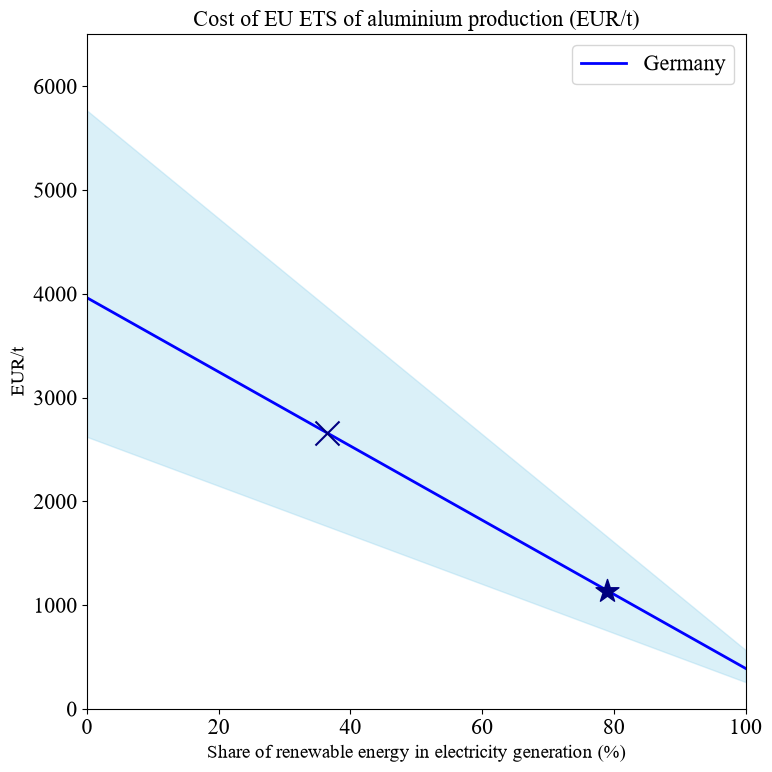

In [109]:
plt.figure(figsize=(8, 8))


plt.fill_between(x_extended, y_min_DE_extended, y_max_DE_extended, alpha=0.3, color='skyblue')

plt.plot(x_extended, y_mean_DE_extended, color='blue', linewidth=2, label='Germany')

plt.scatter(x_values_DE[2], y_mean_DE[2], color='navy', s=300, zorder=5,marker='*')

plt.scatter(DE_2022, y_actual_DE, color='navy', s=300, zorder=5, marker='x')


# Configurar gráfica
plt.xlabel('Share of renewable energy in electricity generation (%)', fontsize=14)
plt.ylabel('EUR/t', fontsize=14)
plt.title('Cost of EU ETS of aluminium production (EUR/t)', fontsize=16)

plt.legend(loc='upper right')
plt.xlim(0, 100)
plt.ylim(0, 6500)

plt.tight_layout()
plt.show()


In [ ]:

print(y_mean_DE[2])


5.1839854891893875
208.89528682695794
220.89859178367945
295.8960085290116
